In [ ]:
# Task 35: Regression Model Evaluation

## Objective
Evaluate a Linear Regression model using Mean Absolute Error
and Mean Squared Error.

## Deliverables
- Prepared salary dataset
- Trained Linear Regression model
- Actual and predicted values
- MAE calculation
- MSE calculation
- Interpretation of evaluation results

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
data = {
    "years_experience": [
        1, 2, 3, 4, 5,
        6, 7, 8, 9, 10,
        11, 12, 13, 14, 15,
        16, 17, 18, 19, 20
    ],

    "annual_salary_inr": [
        300000, 340000, 390000, 420000, 470000,
        500000, 550000, 580000, 630000, 660000,
        710000, 740000, 790000, 820000, 870000,
        900000, 950000, 980000, 1030000, 1060000
    ]
}

df = pd.DataFrame(data)

print("Salary dataset created successfully!")

print("Total records:", len(df))

display(df)

Salary dataset created successfully!
Total records: 20


,years_experience,annual_salary_inr
0,1,300000
1,2,340000
2,3,390000
3,4,420000
4,5,470000
5,6,500000
6,7,550000
7,8,580000
8,9,630000
9,10,660000


In [3]:
df.to_csv(
    "salary_experience_dataset.csv",
    index=False
)

df = pd.read_csv(
    "salary_experience_dataset.csv"
)

print("Dataset loaded successfully!")

display(df.head(10))

Dataset loaded successfully!


,years_experience,annual_salary_inr
0,1,300000
1,2,340000
2,3,390000
3,4,420000
4,5,470000
5,6,500000
6,7,550000
7,8,580000
8,9,630000
9,10,660000


In [4]:
print("DATASET DIMENSIONS")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

DATASET DIMENSIONS
Rows: 20
Columns: 2

Column names:
['years_experience', 'annual_salary_inr']

Data types:
years_experience     int64
annual_salary_inr    int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   years_experience   20 non-null     int64
 1   annual_salary_inr  20 non-null     int64
dtypes: int64(2)
memory usage: 452.0 bytes

Statistical summary:


,years_experience,annual_salary_inr
count,20.00000,2.000000e+01
mean,10.50000,6.845000e+05
std,5.91608,2.370981e+05
min,1.00000,3.000000e+05
25%,5.75000,4.925000e+05
50%,10.50000,6.850000e+05
75%,15.25000,8.775000e+05
max,20.00000,1.060000e+06


In [5]:
X = df[["years_experience"]]

y = df["annual_salary_inr"]

print("INPUT FEATURE (X)")
display(X.head())

print("\nTARGET VARIABLE (y)")
display(y.head())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

INPUT FEATURE (X)


,years_experience
0,1
1,2
2,3
3,4
4,5



TARGET VARIABLE (y)


,annual_salary_inr
0,300000
1,340000
2,390000
3,420000
4,470000



X shape: (20, 1)
y shape: (20,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("TRAINING AND TESTING DATA")

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

TRAINING AND TESTING DATA

Training feature shape: (16, 1)
Testing feature shape: (4, 1)

Training target shape: (16,)
Testing target shape: (4,)

Training records: 16
Testing records: 4


In [7]:
model = LinearRegression()

# Train model using training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [8]:
y_pred = model.predict(X_test)

print("MODEL PREDICTIONS")

for actual, predicted in zip(y_test, y_pred):

    print(
        f"Actual Salary: ₹{actual:,.2f} | "
        f"Predicted Salary: ₹{predicted:,.2f}"
    )

MODEL PREDICTIONS
Actual Salary: ₹300,000.00 | Predicted Salary: ₹305,225.46
Actual Salary: ₹980,000.00 | Predicted Salary: ₹985,917.66
Actual Salary: ₹900,000.00 | Predicted Salary: ₹905,836.22
Actual Salary: ₹340,000.00 | Predicted Salary: ₹345,266.17


In [9]:
predictions_df = pd.DataFrame({
    "years_experience": X_test["years_experience"].values,

    "actual_salary_inr": y_test.values,

    "predicted_salary_inr": np.round(y_pred, 2)
})

# Calculate absolute prediction error
predictions_df["absolute_error_inr"] = (
    predictions_df["actual_salary_inr"] -
    predictions_df["predicted_salary_inr"]
).abs().round(2)

# Sort records by experience
predictions_df = predictions_df.sort_values(
    by="years_experience"
).reset_index(drop=True)

print("ACTUAL VS PREDICTED SALARY COMPARISON")

display(predictions_df)

ACTUAL VS PREDICTED SALARY COMPARISON


,years_experience,actual_salary_inr,predicted_salary_inr,absolute_error_inr
0,1,300000,305225.46,5225.46
1,2,340000,345266.17,5266.17
2,16,900000,905836.22,5836.22
3,18,980000,985917.66,5917.66


In [10]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    y_test,
    y_pred
)

print("=" * 55)
print("           MEAN ABSOLUTE ERROR (MAE)")
print("=" * 55)

print(f"\nMAE: ₹{mae:,.2f}")

print(
    f"\nThe model's average absolute prediction error "
    f"is ₹{mae:,.2f}."
)

           MEAN ABSOLUTE ERROR (MAE)

MAE: ₹5,561.38

The model's average absolute prediction error is ₹5,561.38.


In [11]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(
    y_test,
    y_pred
)

print("=" * 55)
print("           MEAN SQUARED ERROR (MSE)")
print("=" * 55)

print(f"\nMSE: ₹{mse:,.2f} (squared rupees)")

print(
    "\nMSE represents the average of the squared "
    "prediction errors."
)

           MEAN SQUARED ERROR (MSE)

MSE: ₹31,029,545.81 (squared rupees)

MSE represents the average of the squared prediction errors.


In [12]:
evaluation_results = pd.DataFrame({
    "Evaluation Metric": [
        "Mean Absolute Error (MAE)",
        "Mean Squared Error (MSE)"
    ],

    "Value": [
        round(mae, 2),
        round(mse, 2)
    ],

    "Interpretation": [
        "Average absolute prediction error in rupees.",
        "Average squared prediction error in squared rupees."
    ]
})

print("REGRESSION MODEL EVALUATION")

display(evaluation_results)

REGRESSION MODEL EVALUATION


,Evaluation Metric,Value,Interpretation
0,Mean Absolute Error (MAE),5561.38,Average absolute prediction error in rupees.
1,Mean Squared Error (MSE),31029545.81,Average squared prediction error in squared ru...


In [13]:
print("=" * 65)
print("          INTERPRETATION OF REGRESSION RESULTS")
print("=" * 65)

print(
    f"\n1. The Mean Absolute Error is ₹{mae:,.2f}."
)

print(
    "   This represents the average absolute difference "
    "between actual and predicted salaries."
)

print(
    f"\n2. The Mean Squared Error is {mse:,.2f}."
)

print(
    "   It represents the average squared prediction error "
    "and gives larger errors greater weight."
)

print(
    "\n3. The predicted salary values are close to the "
    "actual salary values in the test dataset."
)

print(
    "\n4. Both evaluation metrics help measure the "
    "prediction errors of the regression model."
)

print(
    "\n5. The model performs well on this sample dataset, "
    "which follows an approximately linear pattern."
)

print(
    "\nNote: Results on real-world salary data may differ."
)

          INTERPRETATION OF REGRESSION RESULTS

1. The Mean Absolute Error is ₹5,561.38.
   This represents the average absolute difference between actual and predicted salaries.

2. The Mean Squared Error is 31,029,545.81.
   It represents the average squared prediction error and gives larger errors greater weight.

3. The predicted salary values are close to the actual salary values in the test dataset.

4. Both evaluation metrics help measure the prediction errors of the regression model.

5. The model performs well on this sample dataset, which follows an approximately linear pattern.

Note: Results on real-world salary data may differ.


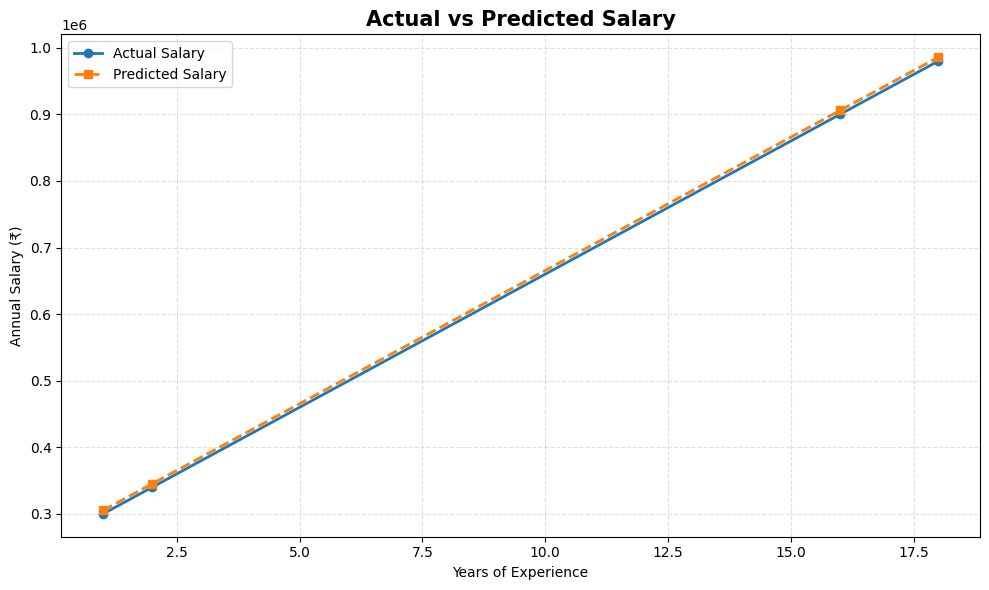

In [14]:
Path("charts").mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

plt.plot(
    predictions_df["years_experience"],
    predictions_df["actual_salary_inr"],
    marker="o",
    linewidth=2,
    label="Actual Salary"
)

plt.plot(
    predictions_df["years_experience"],
    predictions_df["predicted_salary_inr"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Predicted Salary"
)

plt.title(
    "Actual vs Predicted Salary",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Years of Experience")
plt.ylabel("Annual Salary (₹)")

plt.legend()

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

plt.savefig(
    "charts/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
model_summary = pd.DataFrame({
    "Metric": [
        "Total Dataset Records",
        "Training Records",
        "Testing Records",
        "Input Feature",
        "Target Variable",
        "Model",
        "Mean Absolute Error",
        "Mean Squared Error"
    ],

    "Value": [
        len(df),
        len(X_train),
        len(X_test),
        "years_experience",
        "annual_salary_inr",
        "Linear Regression",
        round(mae, 2),
        round(mse, 2)
    ]
})

print("FINAL EVALUATION SUMMARY")

display(model_summary)

FINAL EVALUATION SUMMARY


,Metric,Value
0,Total Dataset Records,20
1,Training Records,16
2,Testing Records,4
3,Input Feature,years_experience
4,Target Variable,annual_salary_inr
5,Model,Linear Regression
6,Mean Absolute Error,5561.38
7,Mean Squared Error,31029545.81


In [16]:
# Save original dataset
df.to_csv(
    "salary_experience_dataset.csv",
    index=False
)

# Save actual and predicted results
predictions_df.to_csv(
    "regression_predictions.csv",
    index=False
)

# Save evaluation summary
model_summary.to_csv(
    "evaluation_summary.csv",
    index=False
)

print("All evaluation files exported successfully!")

All evaluation files exported successfully!


In [17]:
from google.colab import files

files.download("salary_experience_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
files.download("regression_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
files.download("evaluation_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
files.download("charts/actual_vs_predicted.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>